# 04 - Pricing recommendation (Q1 2025)

Goal: find the price per region that gives the highest margin in Q1 2025.

Inputs:
- Q1 demand forecast at today's prices (notebook 02)
- price elasticity (notebook 03)
- variable cost $600/t and plant capacity

Margin = (price - 600) x tons sold, where tons sold can't be more than capacity.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

COST = 600   # variable cost, $/t

forecast = pd.read_csv("data/forecast_Q1_2025.csv", parse_dates=["date"])
hist = pd.read_csv("data/panel_clean.csv", parse_dates=["date"])
regions = sorted(forecast["region"].unique())
today_price = forecast.groupby("region")["price_usd_per_ton"].first()   # Q4 2024 average, used as "today"

In [2]:
# Elasticity - same regression as notebook 03, refitted here
hist["log_demand"] = np.log(hist["demand_tons"])
hist["log_price"] = np.log(hist["price_usd_per_ton"])
hist["log_comp_price"] = np.log(hist["competitor_price_usd_per_ton"])
hist["log_index"] = np.log(hist["industrial_index"])
hist["month"] = hist["date"].dt.month

model = smf.ols("log_demand ~ log_price + promo_flag + log_comp_price + log_index + C(region) + C(month)",
                data=hist).fit()
E = model.params["log_price"]
print(f"elasticity = {E:.2f}")   # +1% price -> about -2% demand

elasticity = -2.06


## Margin at a given price

In [3]:
def q1_margin(region, price, e=E, demand_col="forecast_tons"):
    f = forecast[forecast["region"] == region]
    p0 = today_price[region]

    # demand moves with price through the elasticity:
    # 10% higher price -> demand x 1.10^-2.06 = about 18% lower
    demand = f[demand_col] * (price / p0) ** e

    # we can't sell more than the plant makes, so extra demand is lost
    sold = np.minimum(demand, f["capacity_tons"])

    margin = (price - COST) * sold.sum()
    return margin / 1e6, sold.sum(), (demand - sold).sum()


m, sold, lost = q1_margin("Midwest", today_price["Midwest"])
print(f"Midwest at today's price ${today_price['Midwest']:,.0f}: "
      f"margin ${m:.1f}M, sold {sold:,.0f} t, demand lost {lost:,.0f} t")

Midwest at today's price $1,003: margin $16.1M, sold 39,900 t, demand lost 7,302 t


At today's price the Midwest plant is full (39,900 t = 3 x 13,300) and about 7,300 t of demand can't be served. So we're selling at a low price to customers we can't fully supply.

## Best price per region

Try every price from $800 to $1,500 and keep the one with the highest margin. Two limits:
- don't go above the highest price the region has charged before (elasticity is only known inside that range)
- don't raise more than 10% in one quarter (customers, competitors)

In [4]:
grid = np.arange(800, 1501)
rows = []

for r in regions:
    today = today_price[r]
    max_past = hist.loc[hist["region"] == r, "price_usd_per_ton"].max()

    margins = np.array([q1_margin(r, p)[0] for p in grid])
    best = grid[margins.argmax()]                      # no limits

    ok = (grid <= max_past) & (grid <= today * 1.10)   # apply both limits
    rec = grid[ok][margins[ok].argmax()]

    rows.append([r, round(today), best, round(max_past), rec, round((rec / today - 1) * 100, 1)])

prices = pd.DataFrame(rows, columns=["region", "today", "best (no limits)", "max past price",
                                     "recommended", "change %"]).set_index("region")
prices

,today,best (no limits),max past price,recommended,change %
region,,,,,
Great Lakes,1102,1165,1228,1165,5.7
Gulf Coast,957,1165,1086,1052,9.9
Midwest,1003,1165,1287,1103,10.0
Northeast,927,1165,1250,1019,10.0
Southeast,968,1165,1058,1058,9.3
West,1091,1165,1117,1117,2.4


- With one elasticity for all regions, the unlimited best price comes out the same everywhere: $1,165 = 600 x 2.06 / 1.06.
- Gulf Coast, Southeast and West have never charged that much, so they're capped at their max past price (Southeast $1,058, West $1,117) or by the 10% limit (Gulf Coast).
- Midwest, Northeast and Gulf Coast hit the 10% cap. They can move further in Q2 if Q1 goes as expected.
- Great Lakes reaches $1,165 within 10%. West only moves 2% because it's already close.

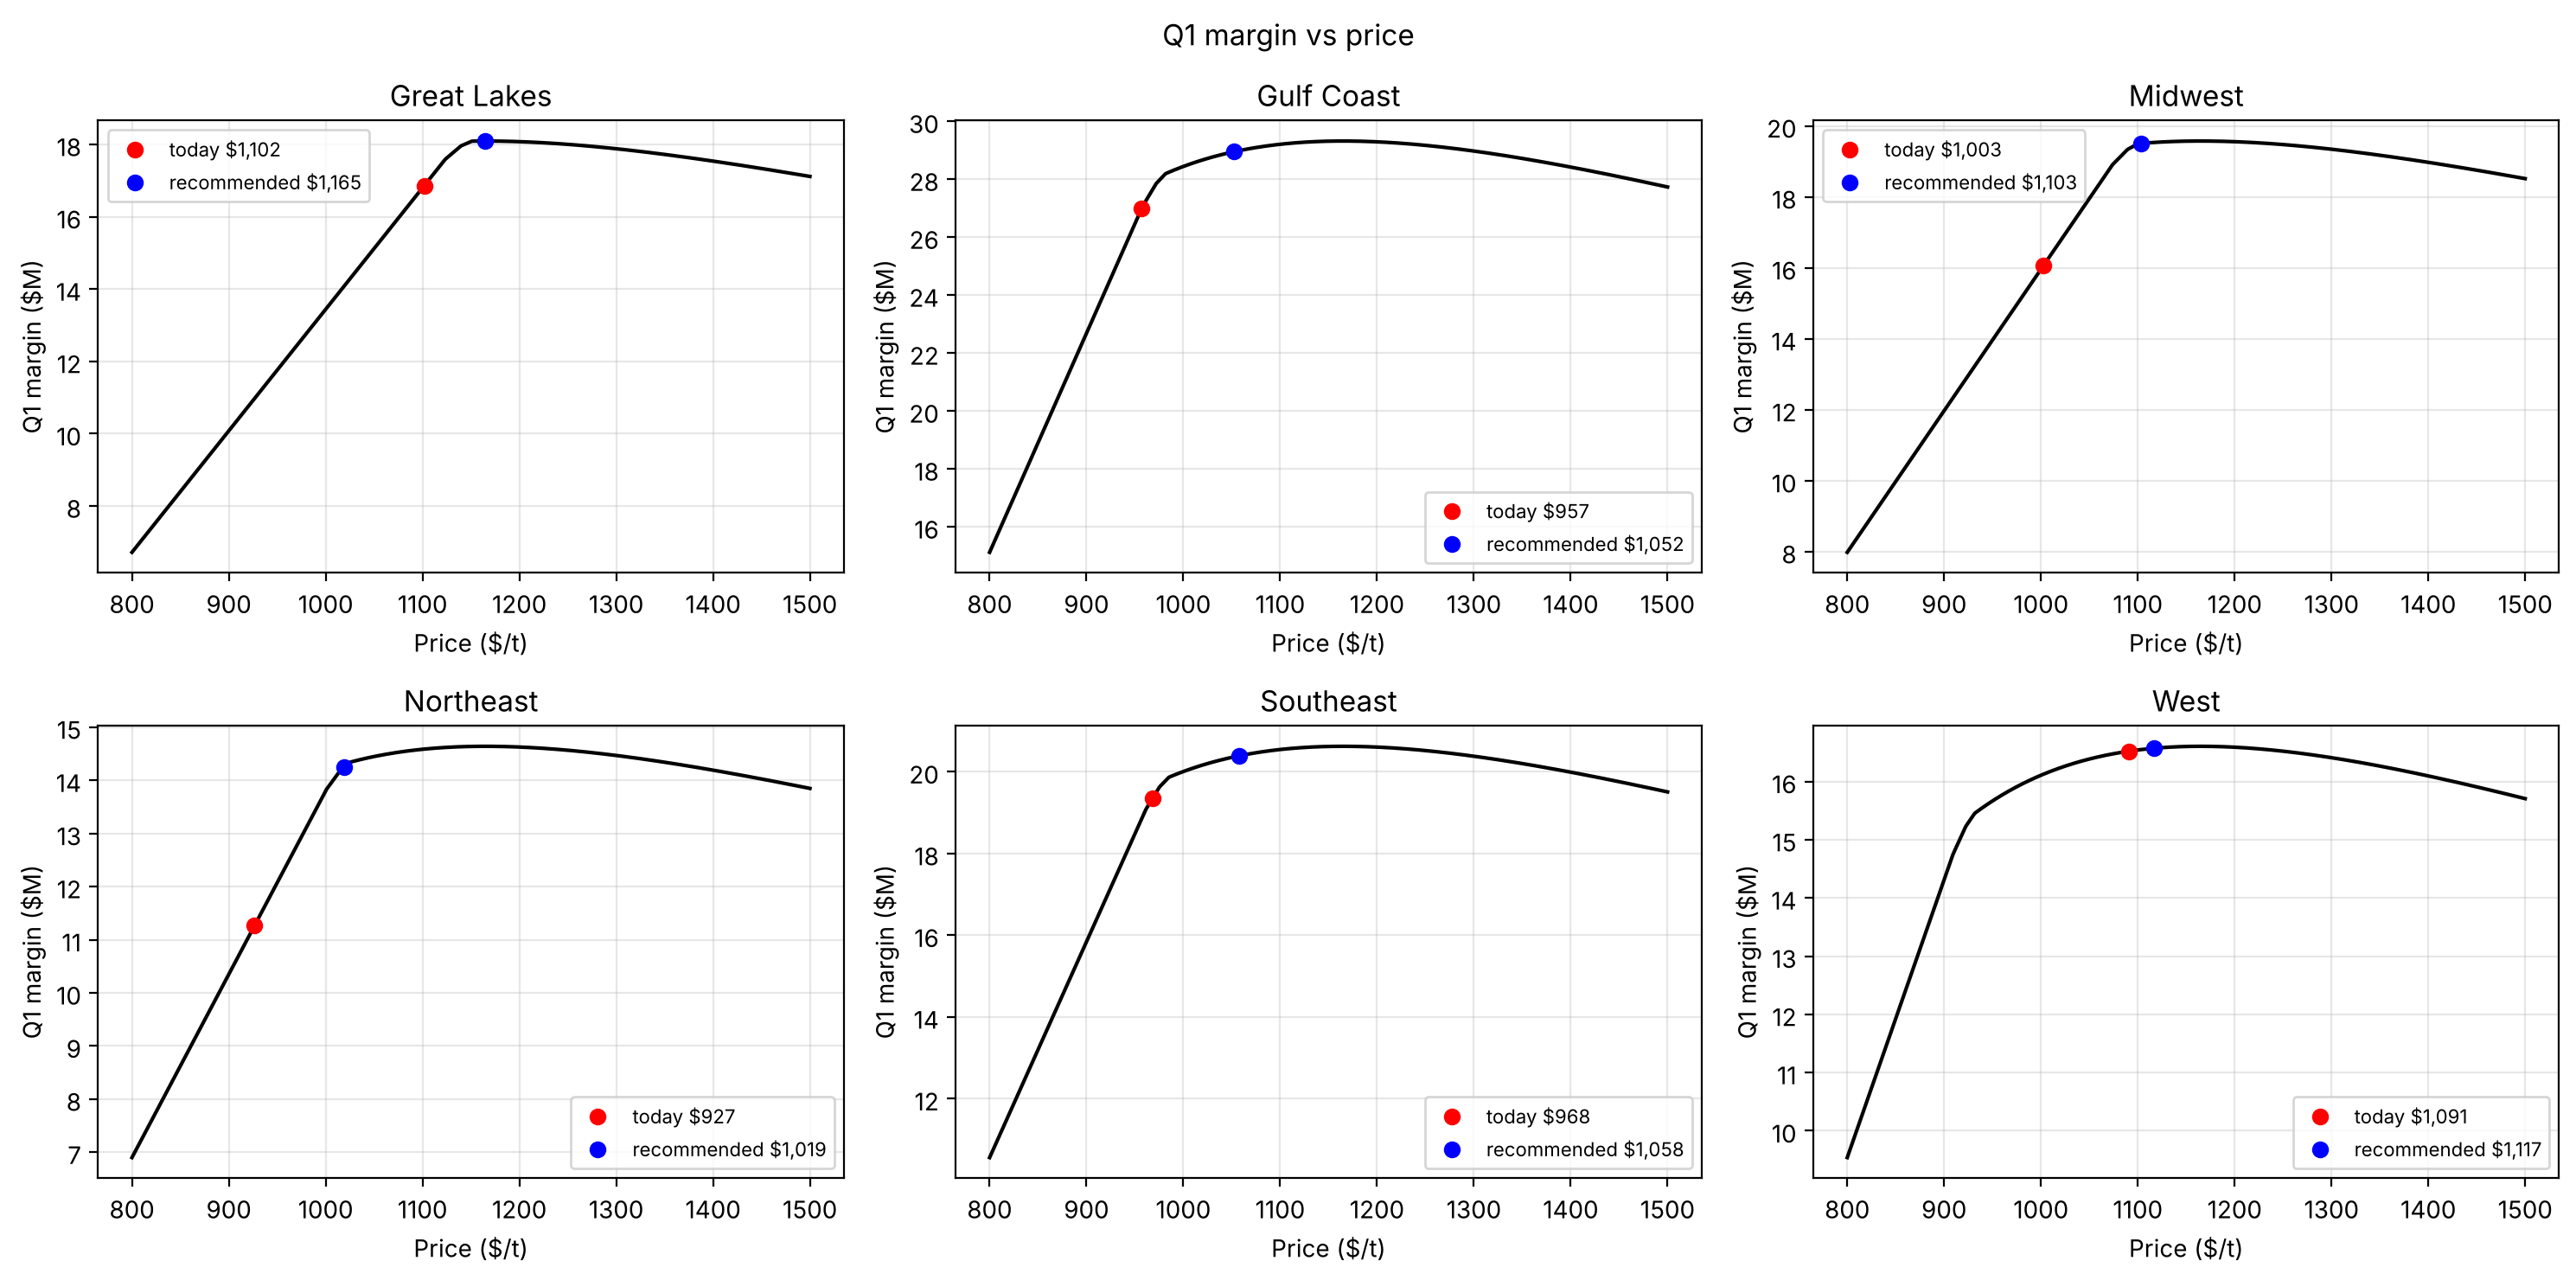

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))

for ax, r in zip(axes.flat, regions):
    ax.plot(grid, [q1_margin(r, p)[0] for p in grid], color="black")
    for p, color, label in [(today_price[r], "red", "today"),
                            (prices.loc[r, "recommended"], "blue", "recommended")]:
        ax.plot(p, q1_margin(r, p)[0], "o", color=color, label=f"{label} ${p:,.0f}")
    ax.set_title(r)
    ax.set_xlabel("Price ($/t)")
    ax.set_ylabel("Q1 margin ($M)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle("Q1 margin vs price")
plt.tight_layout()
plt.show()

The straight steep part on the left is where demand is above capacity. Raising the price there loses no sales, it's pure margin. Today's price (red) sits on that part in most regions. After the bend, higher prices start losing sales and the curve flattens out near the top. The top is flat, so stopping a bit short of the best price (blue vs peak) costs little.

## Impact vs keeping today's prices

In [6]:
rows = []
for r in regions:
    m0, sold0, lost0 = q1_margin(r, today_price[r])
    m1, sold1, _ = q1_margin(r, prices.loc[r, "recommended"])
    rows.append([r, sold0, sold1, lost0, m0, m1, m1 - m0])

impact = pd.DataFrame(rows, columns=["region", "tons today", "tons new", "demand lost today",
                                     "margin today $M", "margin new $M", "extra margin $M"]).set_index("region")
impact.loc["TOTAL"] = impact.sum()
impact.round({"tons today": 0, "tons new": 0, "demand lost today": 0,
              "margin today $M": 1, "margin new $M": 1, "extra margin $M": 1})

,tons today,tons new,demand lost today,margin today $M,margin new $M,extra margin $M
region,,,,,,
Great Lakes,33600.0,32023.0,2324.0,16.9,18.1,1.2
Gulf Coast,75600.0,64042.0,2253.0,27.0,28.9,2.0
Midwest,39900.0,38780.0,7302.0,16.1,19.5,3.4
Northeast,34500.0,33999.0,7049.0,11.3,14.2,3.0
Southeast,52548.0,44526.0,910.0,19.4,20.4,1.0
West,33666.0,32051.0,0.0,16.5,16.6,0.1
TOTAL,269813.0,245421.0,19837.0,107.1,117.8,10.7


- Margin goes from $107.1M to $117.8M: **+$10.7M (+10%)**.
- We sell about 24,000 t less (-9%), but at today's prices about 19,800 t of demand was lost anyway because plants were full.
- Revenue barely moves (about -1.5%). The gain comes from margin per ton, not volume.
- Midwest (+$3.4M) and Northeast (+$3.0M) gain most; West almost nothing.

## What if the inputs are off?

In [7]:
# keep the recommended prices, change one assumption at a time
scenarios = {
    "base case": (E, "forecast_tons"),
    "customers more price-sensitive (-2.5)": (-2.5, "forecast_tons"),
    "customers less price-sensitive (-1.7)": (-1.7, "forecast_tons"),
    "demand at low end of forecast": (E, "low_tons"),
    "demand at high end of forecast": (E, "high_tons"),
}

for name, (e, col) in scenarios.items():
    extra = sum(q1_margin(r, prices.loc[r, "recommended"], e, col)[0]
                - q1_margin(r, today_price[r], e, col)[0] for r in regions)
    print(f"{name:40s} extra margin ${extra:5.1f}M")

base case                                extra margin $ 10.7M
customers more price-sensitive (-2.5)    extra margin $  6.8M
customers less price-sensitive (-1.7)    extra margin $ 13.5M
demand at low end of forecast            extra margin $  5.7M
demand at high end of forecast           extra margin $ 16.9M


The plan makes money in every case, from +$5.7M (weak demand) to +$16.9M (strong demand). Even if customers react much more strongly to price than we estimated (-2.5), it's still +$6.8M.

## Recommendation

Raise Q1 2025 prices to the **recommended** column above: +10% in Midwest, Northeast and Gulf Coast, +9% Southeast, +6% Great Lakes, +2% West. Expected **+$10.7M margin** for the quarter.

Risks:
- competitors may not follow and could undercut us
- big price moves can hurt customer relationships, hence the 10% cap
- the elasticity might be a bit off if past prices were set in reaction to demand

Start with Midwest and Northeast, check actual sales against the forecast each month, and decide the next step for Q2.

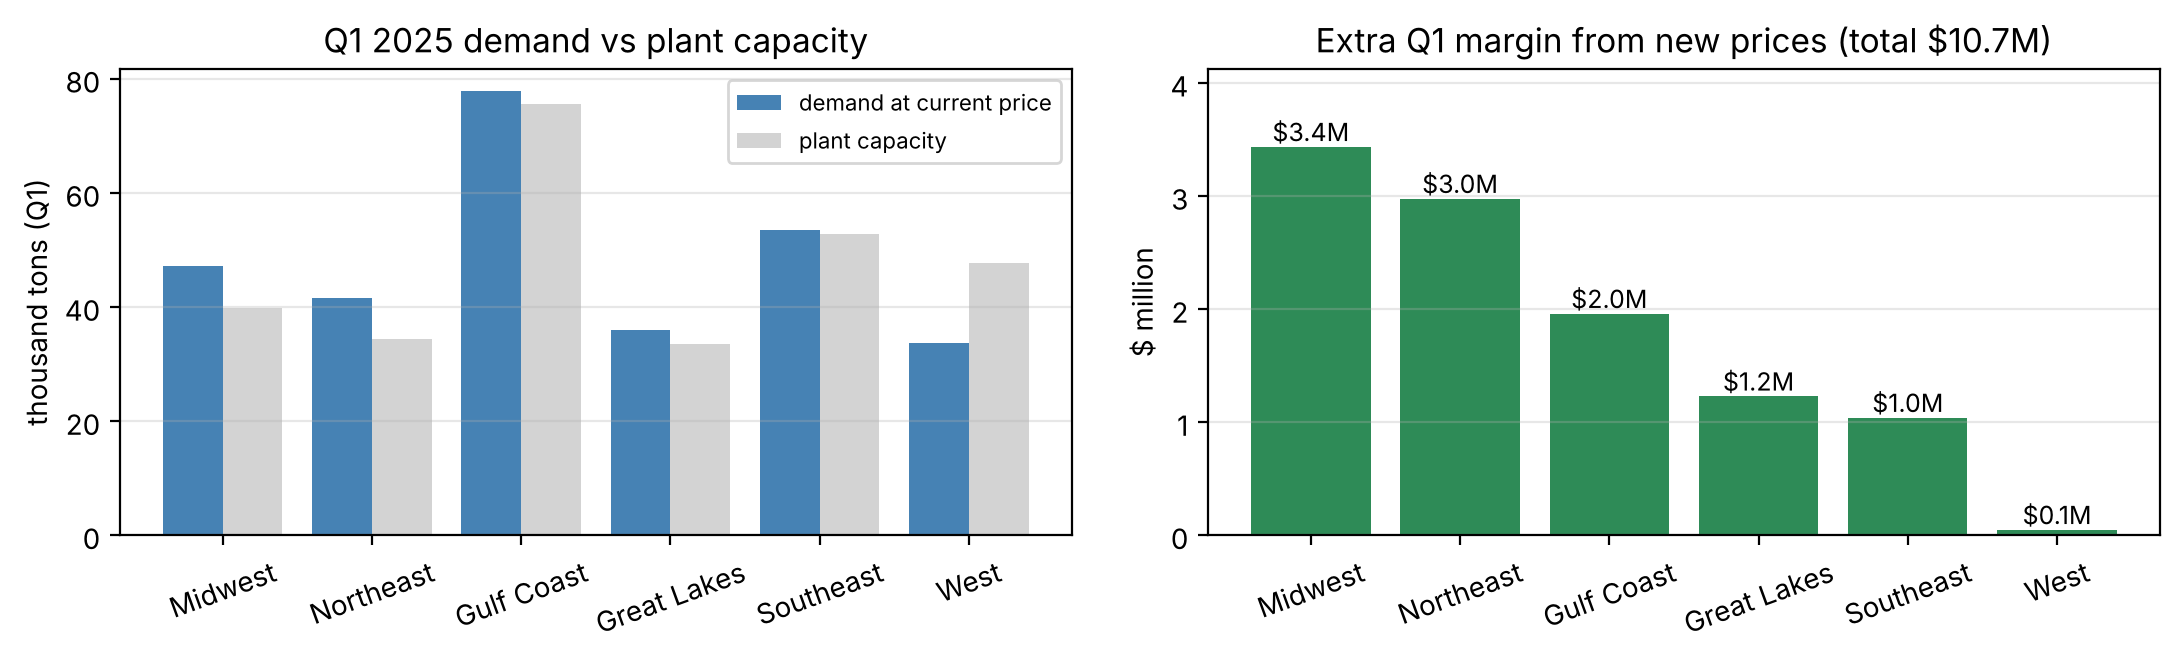

In [8]:
# chart for the one-page summary (SUMMARY.md)
gain = impact.drop("TOTAL")["extra margin $M"].sort_values(ascending=False)
order = gain.index
q1 = forecast.groupby("region")[["forecast_tons", "capacity_tons"]].sum().loc[order] / 1000
x = np.arange(len(order))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

axes[0].bar(x - 0.2, q1["forecast_tons"], 0.4, color="steelblue", label="demand at current price")
axes[0].bar(x + 0.2, q1["capacity_tons"], 0.4, color="lightgrey", label="plant capacity")
axes[0].set_title("Q1 2025 demand vs plant capacity")
axes[0].set_ylabel("thousand tons (Q1)")
axes[0].legend(fontsize=8)

axes[1].bar(x, gain.values, color="seagreen")
for i, v in enumerate(gain.values):
    axes[1].text(i, v + 0.05, f"${v:.1f}M", ha="center", fontsize=9)
axes[1].set_title(f"Extra Q1 margin from new prices (total ${gain.sum():.1f}M)")
axes[1].set_ylabel("$ million")
axes[1].set_ylim(0, gain.max() * 1.2)

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=20)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("SUMMARY_chart.png", dpi=200, bbox_inches="tight")
plt.show()